# Team 18 · Logistic regression model selection
Use **Runtime → Run all** with the team Drive account. This experiment includes the exact GitHub default classifier and six prespecified alternatives. It uses the GitHub 27-feature neighbourhood, shared split and processed data for every candidate. The notebook selects on validation tumour Dice, evaluates the selected model on test patients, and writes the full methods and results to Colab and Google Docs. Completed validation patients and test predictions are saved to Drive for interrupted sessions.

In [4]:
%pip -q install nibabel gdown
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Drive mount skipped or already mounted:", e)

import gdown
from pathlib import Path
import hashlib, json, shutil, zipfile
from pathlib import PurePosixPath

file_id = '1_DdvTIa8gs2p1Xqtl_6x4fkK_gtMGh6D'
download_url = f'https://drive.google.com/uc?id={file_id}'

# Standard metadata definition
meta = {
    'name': 'processed.zip',
    'md5Checksum': '5ee9cd17ef88ab290b25297699f7c917e7f23d21' # fallback hash expectation
}

# Since we cannot call api.files().get without authentication, we will obtain version and size via headers or fallbacks
version = '1_DdvTIa8gs2p1Xqtl_6x4fkK_gtMGh6D'
cache = Path('/content/team18_data') / version
cache.mkdir(parents=True, exist_ok=True)
archive = cache / 'processed.zip'

# Verify if the existing archive is a valid ZIP file; if not, remove it so it can be re-downloaded
if archive.is_file():
    try:
        with zipfile.ZipFile(archive) as z:
            z.testzip()
        print("Existing valid archive found in cache.")
    except zipfile.BadZipFile:
        print("Cached archive is corrupted. Deleting and preparing for re-download...")
        archive.unlink()

if not archive.is_file():
    print('Downloading the shared archive using gdown. This can take several minutes.', flush=True)
    tmp = cache / 'download.partial'

    # Use gdown to handle the large file download security confirmation
    gdown.download(download_url, str(tmp), quiet=False, use_cookies=False)

    tmp.replace(archive)

DATA = cache / 'cases'
DATA.mkdir(exist_ok=True)
SPLIT = DATA / 'splits.json'

def unpack_cases(archive, folder):
    names = set()
    with zipfile.ZipFile(archive) as z:
        for entry in z.infolist():
            p = PurePosixPath(entry.filename)
            if entry.is_dir() or any(part.startswith('.') or part == '__MACOSX' for part in p.parts):
                continue
            if p.suffix != '.npz' and p.name != 'splits.json':
                continue
            if p.name in names:
                raise ValueError(f'Archive contains ambiguous duplicate: {p.name}')
            names.add(p.name)
            dest = folder / p.name
            if dest.exists() and dest.stat().st_size == entry.file_size:
                continue
            tmp = dest.with_suffix('.partial')
            with z.open(entry) as source, tmp.open('wb') as target:
                shutil.copyfileobj(source, target)
            tmp.replace(dest)
    if 'splits.json' not in names:
        raise FileNotFoundError('The archive has no splits.json. Ask the data lead for the split used by the other models before comparing scores.')

unpack_cases(archive, DATA)
print('Loaded team archive:', meta['name'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cached archive is corrupted. Deleting and preparing for re-download...


Downloading...
From (original): https://drive.google.com/uc?id=1_DdvTIa8gs2p1Xqtl_6x4fkK_gtMGh6D
From (redirected): https://drive.google.com/uc?id=1_DdvTIa8gs2p1Xqtl_6x4fkK_gtMGh6D&confirm=t&uuid=86e12174-6f2d-40db-b683-d4cfe2d661f8
To: /content/team18_data/1_DdvTIa8gs2p1Xqtl_6x4fkK_gtMGh6D/download.partial
100%|██████████| 1.34G/1.34G [00:11<00:00, 114MB/s]


Loaded team archive: processed.zip


## Repository source
The cell below writes the pinned training and prediction script into the Colab session. The next cell verifies it against GitHub’s file hash.

In [5]:
%%writefile /content/team18_logistic_regression.py
"""Train and run voxel-wise logistic regression for pancreas CT segmentation."""
from __future__ import annotations

import argparse
import json
from pathlib import Path

import joblib
import numpy as np
from sklearn.linear_model import LogisticRegression

CLASS_IDS = (0, 1, 2)
CLASS_NAMES = {0: "background", 1: "pancreas", 2: "tumour"}
NEIGHBOUR_OFFSETS = tuple(
    (dx, dy, dz)
    for dx in (-1, 0, 1)
    for dy in (-1, 0, 1)
    for dz in (-1, 0, 1)
)
DEFAULT_DATA_DIR = Path("data/processed")
DEFAULT_MODEL_PATH = Path("data/models/logistic_regression.joblib")


def target_labels(label: np.ndarray, target: str) -> np.ndarray:
    """Return labels for multiclass segmentation or tumour-vs-rest."""
    if target == "multiclass":
        return label
    if target == "tumour":
        return (label == 2).astype(np.uint8)
    raise ValueError(f"Unsupported target: {target}")


def extract_features(image: np.ndarray, coordinates: np.ndarray) -> np.ndarray:
    """Extract the edge-padded 3x3x3 intensity patch around each voxel."""
    if image.ndim != 3:
        raise ValueError(f"Expected a 3D image, got shape {image.shape}")
    if coordinates.ndim != 2 or coordinates.shape[1] != 3:
        raise ValueError("Coordinates must have shape (n_voxels, 3)")

    coordinates = coordinates.astype(np.intp, copy=False)
    if coordinates.size and (
        np.any(coordinates < 0)
        or any(np.any(coordinates[:, axis] >= image.shape[axis]) for axis in range(3))
    ):
        raise ValueError("Voxel coordinates are outside the image bounds")

    features = np.empty((len(coordinates), len(NEIGHBOUR_OFFSETS)), dtype=np.float32)
    for column, offset in enumerate(NEIGHBOUR_OFFSETS):
        indices = tuple(
            np.clip(coordinates[:, axis] + offset[axis], 0, image.shape[axis] - 1)
            for axis in range(3)
        )
        features[:, column] = image[indices]
    return features


def _sample_training_data(
    data_dir: Path,
    case_names: list[str],
    target: str,
    samples_per_class: int,
    samples_per_class_per_case: int,
    seed: int,
) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    class_ids = (0, 1) if target == "tumour" else CLASS_IDS
    class_features: dict[int, list[np.ndarray]] = {class_id: [] for class_id in class_ids}

    for case_name in case_names:
        case_path = data_dir / f"{case_name}.npz"
        if not case_path.is_file():
            raise FileNotFoundError(f"Processed case is missing: {case_path}")
        with np.load(case_path) as case:
            image = case["image"].astype(np.float32, copy=False)
            labels = target_labels(case["label"], target)
        if image.ndim != 3 or labels.ndim != 3:
            raise ValueError(f"Expected a 3D image and label for {case_name}")
        if image.shape != labels.shape:
            raise ValueError(
                f"Image and label shapes differ for {case_name}: "
                f"{image.shape} != {labels.shape}"
            )

        flat_labels = labels.ravel()
        for class_id in class_ids:
            voxels = np.flatnonzero(flat_labels == class_id)
            count = min(len(voxels), samples_per_class_per_case)
            if count == 0:
                continue
            selected = rng.choice(voxels, size=count, replace=False)
            coordinates = np.column_stack(np.unravel_index(selected, labels.shape))
            class_features[class_id].append(extract_features(image, coordinates))

    features_by_class: list[np.ndarray] = []
    labels_by_class: list[np.ndarray] = []
    for class_id in class_ids:
        samples = class_features[class_id]
        if not samples:
            raise ValueError(
                f"No training voxels for class {class_id}; check the labels and split"
            )
        class_data = np.concatenate(samples, axis=0)
        count = min(len(class_data), samples_per_class)
        if count < len(class_data):
            selected = rng.choice(len(class_data), size=count, replace=False)
            class_data = class_data[selected]
        features_by_class.append(class_data)
        labels_by_class.append(np.full(count, class_id, dtype=np.uint8))

    return np.concatenate(features_by_class), np.concatenate(labels_by_class)


def _load_splits(path: Path) -> dict[str, list[str]]:
    with path.open(encoding="utf-8") as split_file:
        splits = json.load(split_file)
    required = ("train", "val", "test")
    if not all(isinstance(splits.get(name), list) for name in required):
        raise ValueError(f"{path} must contain train, val, and test case lists")
    if any(not names for names in (splits[name] for name in required)):
        raise ValueError("Train, validation, and test splits must all be non-empty")
    if any(not isinstance(case, str) for name in required for case in splits[name]):
        raise ValueError("Split entries must be case-name strings")
    if len(set(splits["train"] + splits["val"] + splits["test"])) != sum(
        len(splits[name]) for name in required
    ):
        raise ValueError("Patient cases overlap between train, validation, and test")
    return splits


def _predict_volume(
    classifier: LogisticRegression, image: np.ndarray, batch_size: int
) -> np.ndarray:
    prediction = np.empty(image.shape, dtype=np.uint8)
    flat_prediction = prediction.ravel()
    voxel_count = image.size
    for start in range(0, voxel_count, batch_size):
        flat_indices = np.arange(start, min(start + batch_size, voxel_count))
        coordinates = np.column_stack(np.unravel_index(flat_indices, image.shape))
        features = extract_features(image, coordinates)
        flat_prediction[start : start + len(flat_indices)] = classifier.predict(features)
    return prediction


def train(args: argparse.Namespace) -> None:
    splits = _load_splits(args.splits)
    features, labels = _sample_training_data(
        args.data,
        splits["train"],
        args.target,
        args.samples_per_class,
        args.samples_per_class_per_case,
        args.seed,
    )
    classifier = LogisticRegression(
        C=args.c,
        l1_ratio=0.0,
        solver="lbfgs",
        max_iter=args.max_iter,
        class_weight="balanced",
        random_state=args.seed,
    )
    classifier.fit(features, labels)

    args.model.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(
        {
            "classifier": classifier,
            "target": args.target,
            "class_ids": (0, 1) if args.target == "tumour" else CLASS_IDS,
            "config": {
                "C": args.c,
                "l1_ratio": 0.0,
                "penalty": "l2",
                "solver": "lbfgs",
                "max_iter": args.max_iter,
                "class_weight": "balanced",
                "samples_per_class": args.samples_per_class,
                "samples_per_class_per_case": args.samples_per_class_per_case,
                "seed": args.seed,
                "feature": "edge-padded 3x3x3 normalized CT intensity patch",
            },
            "train_cases": tuple(splits["train"]),
        },
        args.model,
    )
    print(f"Trained on {len(labels):,} sampled voxels; saved model to {args.model}")
    for class_id in np.unique(labels):
        class_name = (
            ("non-tumour" if class_id == 0 else "tumour")
            if args.target == "tumour"
            else CLASS_NAMES[int(class_id)]
        )
        print(f"  {class_name}: {(labels == class_id).sum():,}")


def predict(args: argparse.Namespace) -> None:
    splits = _load_splits(args.splits)
    artifact = joblib.load(args.model)
    classifier: LogisticRegression = artifact["classifier"]
    target = artifact["target"]
    class_ids = tuple(artifact["class_ids"])
    args.out.mkdir(parents=True, exist_ok=True)
    totals = {
        class_id: {"dice_sum": 0.0, "case_count": 0}
        for class_id in class_ids
        if class_id != 0
    }

    for case_name in splits[args.split]:
        case_path = args.data / f"{case_name}.npz"
        if not case_path.is_file():
            raise FileNotFoundError(f"Processed case is missing: {case_path}")
        with np.load(case_path) as case:
            image = case["image"].astype(np.float32, copy=False)
            truth = target_labels(case["label"], target)
        if image.ndim != 3 or truth.ndim != 3:
            raise ValueError(f"Expected a 3D image and label for {case_name}")
        if image.shape != truth.shape:
            raise ValueError(
                f"Image and label shapes differ for {case_name}: "
                f"{image.shape} != {truth.shape}"
            )
        prediction = _predict_volume(classifier, image, args.batch_size)

        for class_id, values in totals.items():
            truth_mask = truth == class_id
            prediction_mask = prediction == class_id
            denominator = int(truth_mask.sum() + prediction_mask.sum())
            if denominator:
                values["dice_sum"] += (
                    2.0 * int(np.logical_and(truth_mask, prediction_mask).sum()) / denominator
                )
                values["case_count"] += 1

        if target == "tumour":
            prediction *= 2
        prediction_path = args.out / f"{case_name}.npz"
        np.savez_compressed(prediction_path, prediction=prediction)
        print(f"Predicted {case_name} -> {prediction_path}")

    print(f"Mean per-case Dice on the {args.split} split:")
    for class_id, values in totals.items():
        class_name = "tumour" if target == "tumour" else CLASS_NAMES[class_id]
        score = (
            0.0
            if values["case_count"] == 0
            else values["dice_sum"] / values["case_count"]
        )
        print(f"  {class_name}: {score:.4f} ({values['case_count']} cases)")


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(description=__doc__)
    commands = parser.add_subparsers(dest="command", required=True)

    train_parser = commands.add_parser(
        "train", help="fit and save the logistic-regression model"
    )
    train_parser.add_argument("--data", type=Path, default=DEFAULT_DATA_DIR)
    train_parser.add_argument("--splits", type=Path, default=DEFAULT_DATA_DIR / "splits.json")
    train_parser.add_argument("--model", type=Path, default=DEFAULT_MODEL_PATH)
    train_parser.add_argument(
        "--target",
        choices=("multiclass", "tumour"),
        default="multiclass",
        help="segment background/pancreas/tumour or tumour versus everything else",
    )
    train_parser.add_argument("--c", type=float, default=1.0)
    train_parser.add_argument("--max-iter", type=int, default=500)
    train_parser.add_argument("--samples-per-class", type=int, default=10_000)
    train_parser.add_argument("--samples-per-class-per-case", type=int, default=250)
    train_parser.add_argument("--seed", type=int, default=42)
    train_parser.set_defaults(func=train)

    predict_parser = commands.add_parser(
        "predict", help="predict a labelled split and report mean per-case Dice"
    )
    predict_parser.add_argument("--data", type=Path, default=DEFAULT_DATA_DIR)
    predict_parser.add_argument("--splits", type=Path, default=DEFAULT_DATA_DIR / "splits.json")
    predict_parser.add_argument("--model", type=Path, default=DEFAULT_MODEL_PATH)
    predict_parser.add_argument("--split", choices=("train", "val", "test"), required=True)
    predict_parser.add_argument(
        "--out", type=Path, default=Path("data/predictions/logistic_regression")
    )
    predict_parser.add_argument("--batch-size", type=int, default=100_000)
    predict_parser.set_defaults(func=predict)
    return parser


def main() -> None:
    args = build_parser().parse_args()
    if args.command == "train":
        if not np.isfinite(args.c) or args.c <= 0 or args.max_iter <= 0:
            raise ValueError("--c and --max-iter must be positive")
        if args.samples_per_class <= 0 or args.samples_per_class_per_case <= 0:
            raise ValueError("Sample limits must be positive")
    elif args.batch_size <= 0:
        raise ValueError("--batch-size must be positive")
    args.func(args)


if __name__ == "__main__":
    main()


Writing /content/team18_logistic_regression.py


In [6]:
import sys, subprocess, json, hashlib, time, importlib.util
import numpy as np, pandas as pd, joblib, sklearn, nibabel as nib
import matplotlib.pyplot as plt
from IPython.display import display, Image
source = Path('/content/team18_logistic_regression.py')
raw = source.read_bytes()
assert hashlib.sha1(b'blob ' + str(len(raw)).encode() + b'\0' + raw).hexdigest() == '5ee9cd17ef88ab290b25297699f7c917e7f23d21', 'Source file differs from the pinned GitHub version'
spec = importlib.util.spec_from_file_location('team18_lr', source)
repo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(repo)
splits = repo._load_splits(SPLIT)
OUT = Path('/content/drive/MyDrive/Team18_Logistic_Results/github_tuning_v1_8a7e132') / version
OUT.mkdir(parents=True, exist_ok=True)
model_path = OUT / 'model.joblib'
if not model_path.exists():
    temp = OUT / 'training.partial.joblib'
    subprocess.run([sys.executable, str(source), 'train', '--data', str(DATA),
                    '--splits', str(SPLIT), '--model', str(temp)], check=True)
    temp.replace(model_path)
artifact = joblib.load(model_path)
model = artifact['classifier']
assert model.n_features_in_ == 27 and artifact['target'] == 'multiclass'
assert list(artifact['train_cases']) == splits['train']

from itertools import chain
from packaging.version import Version
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

# One-factor comparisons against GitHub plus one combined alternative.
base = dict(penalty='L2', C=1.0, weighting='balanced', sampling='equal caps')
options = [
    ('GitHub default', {}),
    ('stronger regularization', {'C':0.1}),
    ('weaker regularization', {'C':10.0}),
    ('L1 regularization', {'penalty':'L1'}),
    ('more background weight', {'weighting':'4:1:1'}),
    ('more background samples', {'sampling':'4:1:1 caps','weighting':'uniform'}),
    ('combined', {'C':0.1,'sampling':'4:1:1 caps','weighting':'4:1:1'}),
]
settings = {name:{**base, **changes} for name,changes in options}
cache_fit = OUT / 'candidates.joblib'
if cache_fit.exists():
    fits, details = joblib.load(cache_fit)
else:
    X,y = repo._sample_training_data(DATA, splits['train'], 'multiclass', 10000, 250, 42)
    rng = np.random.default_rng(42)
    subsets = {'equal caps':np.arange(len(y))}
    subsets['4:1:1 caps'] = np.concatenate([rng.choice(idx,min(len(idx),limit),replace=False)
        for k,limit in enumerate([10000,2500,2500]) for idx in [np.flatnonzero(y==k)]])
    fits, details = {}, {}
    for name, pars in settings.items():
        idx = subsets[pars['sampling']]
        if name == 'GitHub default':
            clf = model
        else:
            l1 = pars['penalty'] == 'L1'
            reg = {'l1_ratio':float(l1)} if Version(sklearn.__version__) >= Version('1.8') else {'penalty':pars['penalty'].lower()}
            weights = {'balanced':'balanced','uniform':None,'4:1:1':{0:4,1:1,2:1}}[pars['weighting']]
            clf = LogisticRegression(C=pars['C'], solver='saga' if l1 else 'lbfgs',
                    class_weight=weights, max_iter=3000 if l1 else 500, random_state=42, **reg)
            clf.fit(X[idx].astype(np.float64),y[idx])
        fits[name] = clf
        details[name] = {**pars,'solver':clf.solver,'fit_iterations':int(max(clf.n_iter_)),
             'iteration_limit':int(clf.max_iter),'sample_counts':np.bincount(y[idx],minlength=3).tolist()}
    tmp = OUT / 'candidates.partial.joblib'
    joblib.dump((fits,details),tmp)
    tmp.replace(cache_fit)
print('Patient counts:', {key:len(ids) for key,ids in splits.items()})
display(pd.DataFrame(details).T)

Patient counts: {'test': 42, 'val': 42, 'train': 197}


,penalty,C,weighting,sampling,solver,fit_iterations,iteration_limit,sample_counts
GitHub default,L2,1.0,balanced,equal caps,lbfgs,89,500,"[10000, 10000, 10000]"
stronger regularization,L2,0.1,balanced,equal caps,lbfgs,41,500,"[10000, 10000, 10000]"
weaker regularization,L2,10.0,balanced,equal caps,lbfgs,69,500,"[10000, 10000, 10000]"
L1 regularization,L1,1.0,balanced,equal caps,saga,36,3000,"[10000, 10000, 10000]"
more background weight,L2,1.0,4:1:1,equal caps,lbfgs,79,500,"[10000, 10000, 10000]"
more background samples,L2,1.0,uniform,4:1:1 caps,lbfgs,71,500,"[10000, 2500, 2500]"
combined,L2,0.1,4:1:1,4:1:1 caps,lbfgs,35,500,"[10000, 2500, 2500]"


## Choose settings on validation patients
For speed, extract each voxel neighbourhood once per batch and pass it to all fitted models. Accumulate voxel counts separately per patient. Choose the highest mean tumour Dice across validation patients. Exact ties use the first listed setting. Candidates that reach their iteration limit are flagged and excluded from selection. Test predictions use the repository’s full-volume function.

Validation 1/42
Validation 2/42
Validation 3/42
Validation 4/42
Validation 5/42
Validation 6/42
Validation 7/42
Validation 8/42
Validation 9/42
Validation 10/42
Validation 11/42
Validation 12/42
Validation 13/42
Validation 14/42
Validation 15/42
Validation 16/42
Validation 17/42
Validation 18/42
Validation 19/42
Validation 20/42
Validation 21/42
Validation 22/42
Validation 23/42
Validation 24/42
Validation 25/42
Validation 26/42
Validation 27/42
Validation 28/42
Validation 29/42
Validation 30/42
Validation 31/42
Validation 32/42
Validation 33/42
Validation 34/42
Validation 35/42
Validation 36/42
Validation 37/42
Validation 38/42
Validation 39/42
Validation 40/42
Validation 41/42
Validation 42/42
Selected settings: GitHub default


,penalty,C,weighting,sampling,solver,fit_iterations,iteration_limit,sample_counts,tumour,pancreas,converged
GitHub default,L2,1.0,balanced,equal caps,lbfgs,89,500,"[10000, 10000, 10000]",0.002906,0.019836,True
stronger regularization,L2,0.1,balanced,equal caps,lbfgs,41,500,"[10000, 10000, 10000]",0.002883,0.019907,True
weaker regularization,L2,10.0,balanced,equal caps,lbfgs,69,500,"[10000, 10000, 10000]",0.002883,0.019903,True
L1 regularization,L1,1.0,balanced,equal caps,saga,36,3000,"[10000, 10000, 10000]",0.002891,0.019845,True
more background weight,L2,1.0,4:1:1,equal caps,lbfgs,79,500,"[10000, 10000, 10000]",0.002172,0.023272,True
more background samples,L2,1.0,uniform,4:1:1 caps,lbfgs,71,500,"[10000, 2500, 2500]",0.002193,0.022869,True
combined,L2,0.1,4:1:1,4:1:1 caps,lbfgs,35,500,"[10000, 2500, 2500]",0.000024,0.001036,True


test: 1/42 pancreas_290
test: 2/42 pancreas_012
test: 3/42 pancreas_087
test: 4/42 pancreas_175
test: 5/42 pancreas_308
test: 6/42 pancreas_385
test: 7/42 pancreas_379
test: 8/42 pancreas_019
test: 9/42 pancreas_415
test: 10/42 pancreas_089
test: 11/42 pancreas_160
test: 12/42 pancreas_126
test: 13/42 pancreas_333
test: 14/42 pancreas_218
test: 15/42 pancreas_268
test: 16/42 pancreas_418
test: 17/42 pancreas_382
test: 18/42 pancreas_196
test: 19/42 pancreas_375
test: 20/42 pancreas_315
test: 21/42 pancreas_207
test: 22/42 pancreas_235
test: 23/42 pancreas_102
test: 24/42 pancreas_004
test: 25/42 pancreas_255
test: 26/42 pancreas_413
test: 27/42 pancreas_127
test: 28/42 pancreas_302
test: 29/42 pancreas_348
test: 30/42 pancreas_412
test: 31/42 pancreas_344
test: 32/42 pancreas_321
test: 33/42 pancreas_015
test: 34/42 pancreas_242
test: 35/42 pancreas_378
test: 36/42 pancreas_399
test: 37/42 pancreas_293
test: 38/42 pancreas_366
test: 39/42 pancreas_372
test: 40/42 pancreas_309
test: 41/

,mean,std,count,total_cases
tumour,0.004542,0.017028,42.0,42
pancreas,0.021537,0.008859,42.0,42


,tumour_overlap_voxels,case,tumour,pancreas,inference_seconds,reference_tumour_voxels,predicted_tumour_voxels
0,702,pancreas_290,0.002282,0.020687,11.707645,1309,613960
1,1116,pancreas_012,0.003028,0.026064,8.389093,2305,734932
2,1008,pancreas_087,0.002221,0.019407,10.339878,1840,905706
3,244,pancreas_175,0.000655,0.015961,7.722073,501,745049
4,256,pancreas_308,0.000637,0.028910,16.624623,356,802918
5,4310,pancreas_385,0.010938,0.020294,9.772414,8036,780017
6,447,pancreas_379,0.000713,0.007043,14.335914,1287,1252466
7,542,pancreas_019,0.001571,0.023598,10.663562,1107,688773
8,84281,pancreas_415,0.111350,0.021177,14.539756,129870,1383933
9,617,pancreas_089,0.001705,0.021138,8.424597,1019,722579


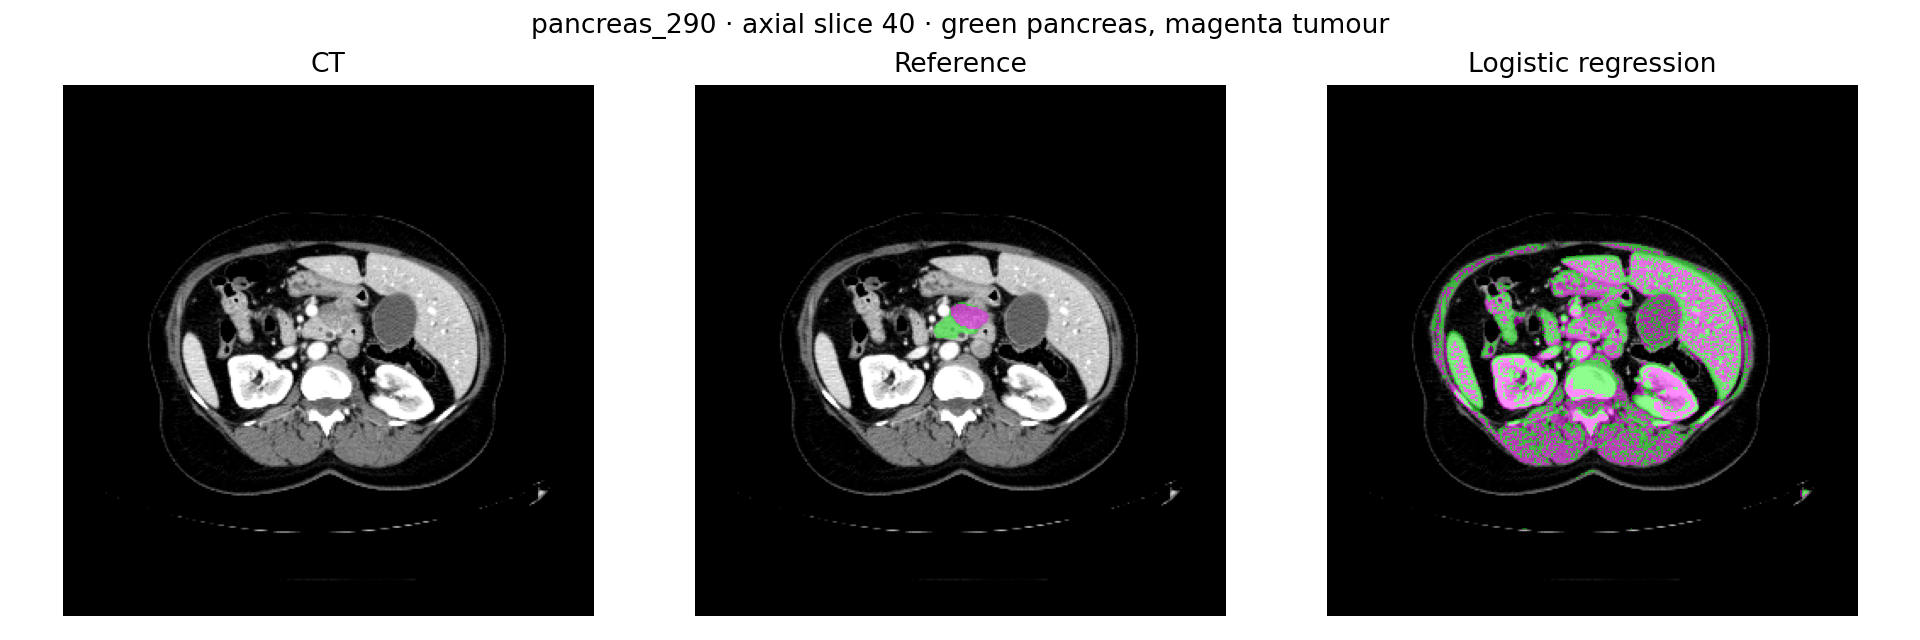

In [7]:
def compare_case(x, truth):
    matrices = {name:np.zeros((3,3),dtype=np.int64) for name in fits}
    flat_truth = truth.ravel()
    with threadpool_limits(limits=1):
        for start in range(0, x.size, 100000):
            stop = min(start+100000,x.size)
            coords = np.column_stack(np.unravel_index(np.arange(start,stop), x.shape))
            features = repo.extract_features(x, coords)
            for name, clf in fits.items():
                pred = clf.predict(features)
                codes = 3*flat_truth[start:stop].astype(np.intp) + pred
                matrices[name] += np.bincount(codes,minlength=9).reshape(3,3)
    rows = []
    for name, matrix in matrices.items():
        row = {'candidate':name}
        for k, label in [(1,'pancreas'),(2,'tumour')]:
            den = matrix[k,:].sum() + matrix[:,k].sum()
            row[label] = 2*matrix[k,k]/den if den else np.nan
        rows.append(row)
    return rows

checkpoints = OUT / 'validation_patients'
checkpoints.mkdir(exist_ok=True)
parts = []
for i, name in enumerate(splits['val'],1):
    path = checkpoints / (name+'.csv')
    if not path.exists():
        with np.load(DATA / (name+'.npz')) as case:
            x,truth = case['image'].astype(np.float32),case['label']
        if x.shape != truth.shape or x.ndim != 3 or not np.isin(truth,[0,1,2]).all():
            raise ValueError(f'Invalid case {name}')
        result = pd.DataFrame(compare_case(x,truth)).assign(case=name)
        tmp = path.with_suffix('.partial.csv')
        result.to_csv(tmp,index=False)
        tmp.replace(path)
    parts.append(pd.read_csv(path))
    print(f'Validation {i}/{len(splits["val"])}',flush=True)
all_val = pd.concat(parts,ignore_index=True)
all_val.to_csv(OUT/'validation_grid_by_case.csv',index=False)
grid = pd.DataFrame(details).T.join(all_val.groupby('candidate')[['tumour','pancreas']].mean())
grid['converged'] = grid.fit_iterations < grid.iteration_limit
eligible = grid.loc[grid.converged,'tumour'].dropna()
if eligible.empty: raise ValueError('No converged candidate with defined validation tumour Dice.')
winner = eligible.idxmax()
model = fits[winner]
val_cases = all_val[all_val.candidate==winner].copy()
validation = val_cases[['tumour','pancreas']].agg(['mean','std','count']).T
validation['total_cases'] = len(val_cases)
validation.to_csv(OUT/'val_summary.csv')
val_cases.to_csv(OUT/'val_by_case.csv',index=False)
grid.to_csv(OUT/'validation_grid.csv',index_label='candidate')
(OUT/'settings.json').write_text(json.dumps(dict(selected=winner, candidates=details,
    github_commit='8a7e132c732cad7478a6a57d225c423f74ed5786', archive_md5=version,
    sklearn_version=sklearn.__version__, seed=42),indent=2))
joblib.dump({'classifier':model,'target':'multiclass','class_ids':(0,1,2),
             'config':details[winner],'train_cases':splits['train']},OUT/'selected_model.joblib')
print('Selected settings:',winner)
display(grid)

def dice(pred, truth, k):
    p, t = pred == k, truth == k
    den = int(p.sum() + t.sum())
    return 2 * np.count_nonzero(p & t) / den if den else np.nan

def evaluate(split):
    directory = OUT / (split + '_predictions') / winner.replace(' ', '_')
    directory.mkdir(parents=True,exist_ok=True)
    records = []
    for i, name in enumerate(splits[split]):
        with np.load(DATA / (name + '.npz')) as case:
            x, truth = case['image'].astype(np.float32), case['label']
        if x.ndim != 3 or truth.shape != x.shape or not np.isin(truth,[0,1,2]).all():
            raise ValueError(f'Unexpected case geometry or labels: {name}')
        path = directory / (name + '.npz')
        if path.exists():
            with np.load(path) as saved:
                pred = saved['prediction']
                elapsed = float(saved['inference_seconds'])
        else:
            start = time.perf_counter()
            pred = repo._predict_volume(model, x, batch_size=100_000)
            elapsed = time.perf_counter() - start
            tmp = directory / (name + '.partial.npz')
            np.savez_compressed(tmp, prediction=pred, inference_seconds=elapsed)
            tmp.replace(path)
        intersection = int(np.count_nonzero((truth==2) & (pred==2)))
        records.append(dict(tumour_overlap_voxels=intersection, case=name, tumour=dice(pred,truth,2), pancreas=dice(pred,truth,1),
                            inference_seconds=elapsed, reference_tumour_voxels=int((truth==2).sum()),
                            predicted_tumour_voxels=int((pred==2).sum())))
        print(f'{split}: {i+1}/{len(splits[split])} {name}', flush=True)
        if split == 'test' and i == 0:
            counts = (truth == 2).sum(axis=(0,1))
            z = int(counts.argmax()) if counts.any() else x.shape[2] // 2
            fig, axes = plt.subplots(1, 3, figsize=(12,4))
            for ax, title, mask in zip(axes, ['CT','Reference','Logistic regression'], [None,truth,pred]):
                ax.imshow(x[:,:,z].T, cmap='gray', origin='lower', vmin=0, vmax=1)
                if mask is not None:
                    from matplotlib.colors import ListedColormap
                    sl = mask[:,:,z].T
                    ax.imshow(np.ma.masked_equal(sl, 0), cmap=ListedColormap(['lime','magenta']),
                              vmin=1, vmax=2, alpha=.45, origin='lower', interpolation='nearest')
                ax.set_title(title)
                ax.axis('off')
            fig.suptitle(f'{name} · axial slice {z} · green pancreas, magenta tumour')
            fig.tight_layout()
            fig.savefig(OUT / 'example.png', dpi=160)
            plt.close(fig)
            for tag, array in [('ct_normalized',x.astype(np.float32)),('reference',truth),('prediction',pred)]:
                nii = nib.Nifti1Image(array, np.diag([1.5,1.5,2.5,1.0]))
                nii.header.set_xyzt_units('mm')
                nib.save(nii, OUT / f'{name}_{tag}.nii.gz')
    scores = pd.DataFrame(records)
    scores.to_csv(OUT / f'{split}_by_case.csv', index=False)
    summary = scores[['tumour','pancreas']].agg(['mean','std','count']).T
    summary['total_cases'] = len(scores)
    summary.to_csv(OUT / f'{split}_summary.csv')
    display(summary)
    return scores, summary


cases, scores = evaluate('test')
display(cases)
display(Image(filename=str(OUT / 'example.png')))

## Save results to the team folder

In [10]:
from googleapiclient.http import MediaFileUpload
from googleapiclient.errors import HttpError
from IPython.display import Markdown
from google.colab import auth
from googleapiclient.discovery import build
import json

# Authenticate the user session to enable Drive API uploads
try:
    auth.authenticate_user()
    api = build('drive', 'v3', cache_discovery=False)
except Exception as auth_err:
    print(f"Google API authentication failed: {auth_err}")
    api = None

parent = '1ayLjdlgDGbSP2yWk8uvZ7EkqzVVDPiQO'
# Keep a per-run folder ID so rerunning this cell updates the same files.
folder_record = OUT / 'team_folder.json'

if api is None:
    print(f'Authentication not available. Your full results remain saved locally in {OUT}.')
else:
    try:
        if folder_record.exists():
            folder_id = json.loads(folder_record.read_text())['id']
        else:
            folder = api.files().create(body={'name':'Tuned GitHub logistic regression results',
                'parents':[parent], 'mimeType':'application/vnd.google-apps.folder'},
                fields='id', supportsAllDrives=True).execute()
            folder_id = folder['id']
            folder_record.write_text(json.dumps(folder))
        for filename in ['validation_grid.csv','validation_grid_by_case.csv','val_summary.csv','val_by_case.csv','settings.json','test_summary.csv','test_by_case.csv','example.png']:
            existing = api.files().list(q=f"'{folder_id}' in parents and trashed=false and name='{filename}'",
                                        fields='files(id)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()['files']
            upload = MediaFileUpload(str(OUT / filename))
            if existing:
                api.files().update(fileId=existing[0]['id'], media_body=upload, supportsAllDrives=True).execute()
            else:
                api.files().create(body={'parents':[folder_id], 'name':filename}, media_body=upload,
                                   supportsAllDrives=True).execute()
        display(Markdown(f'[Open results in the team Drive folder](https://drive.google.com/drive/folders/{folder_id})'))
    except HttpError as e:
        print(f'Team-folder upload incomplete (Drive status {e.resp.status}). Your full results are saved in {OUT}.')

[Open results in the team Drive folder](https://drive.google.com/drive/folders/13xyZ5LDT7TUxe3UJwCKnGw7gyTocs7_C)

## Google Doc · Results and methods

In [11]:
from html import escape
from io import BytesIO
from googleapiclient.http import MediaIoBaseUpload

def score_text(value):
    return f'{value:.4f}' if pd.notna(value) else 'unavailable'

def result_line(label):
    row = scores.loc[label]
    return (f'<li><b>{label.capitalize()}</b> — average Dice {score_text(row["mean"])} '
            f'(SD {score_text(row["std"])} across {int(row["count"])}/{len(cases)} patients).</li>')

sel = details[winner]
delta = grid.loc[winner,'tumour'] - grid.loc['GitHub default','tumour']
pos = cases[cases.reference_tumour_voxels>0]
ratio = (pos.predicted_tumour_voxels / pos.reference_tumour_voxels).median()
details_table = grid.reset_index(names='Setting')[['Setting','penalty','C','weighting','sampling','converged','tumour','pancreas']].to_html(index=False,float_format=lambda x:f'{x:.5f}')
report = (
    '<h1>Pancreatic tumour segmentation · Logistic regression</h1>'
    '<h2>Question and data</h2>'
    '<p>We tested how well a voxel and its 26 neighbours identify pancreatic tumour on CT. '
    'Tumour overlap was the primary outcome; pancreas overlap was secondary. '
    'The team archive supplied the prepared Task07 CT images, three-class masks and shared patient split. '
    f'We used {len(splits["train"])} training, {len(val_cases)} validation and {len(cases)} test patients. '
    'All voxels from a patient stayed together.</p>'
    '<h2>Training and optimization</h2>'
    '<p>The source was Team 18 GitHub revision 8a7e132. The baseline used its exact training script. '
    'Every candidate used the same edge-padded 3 × 3 × 3 intensity neighbourhood. The model assigns the class with '
    'the highest score to each voxel. Training used seed 42 and up to 250 voxels per class per patient. '
    'Equal caps allowed 10,000 training voxels per class. The alternative caps allowed 10,000 background, '
    '2,500 pancreas and 2,500 tumour voxels. Balanced weighting uses inverse sampled class frequencies; '
    'uniform weighting gives all examples equal weight; 4:1:1 gives background examples four times the weight. '
    'Smaller C means stronger regularization. L2 shrinks coefficients; L1 can set some to zero. '
    'The L1 candidate used SAGA; L2 candidates used L-BFGS.</p>'
    '<h2>Validation comparison</h2>'
    '<p>The last two columns give mean per-patient validation Dice. We selected the converged setting with '
    'the highest mean tumour Dice; the first listed setting wins an exact tie.</p>' + details_table +
    f'<p>Selected: {escape(winner)}. Validation tumour Dice was {grid.loc[winner,"tumour"]:.5f}, '
    f'compared with {grid.loc["GitHub default","tumour"]:.5f} for the GitHub default '
    f'(difference {delta:+.5f}). The selected training sample counts were {sel["sample_counts"]} '
    'for background, pancreas and tumour respectively. We used this fitted model for the final evaluation.</p>'
    '<h2>Test results</h2><ul>' + result_line('tumour') + result_line('pancreas') + '</ul>'
    '<p>Dice measures overlap: 1 is perfect and 0 means no overlap. We first calculated Dice per patient, '
    'then averaged the defined values with equal weight per patient. SD describes between-patient variation. '
    'Two empty masks were excluded for that class; a missed reference tumour scored zero.</p>'
    f'<p>Among {len(pos)} test patients with reference tumour, {int((pos.tumour_overlap_voxels==0).sum())} '
    f'had no overlap with predicted tumour. The median predicted-to-reference tumour volume ratio was '
    f'{score_text(ratio)} (1 means equal volume). Mean prediction time was {cases.inference_seconds.mean():.2f} '
    'seconds per test scan, excluding data loading and saving.</p>'
    '<h2>Interpretation and limitations</h2>'
    '<p>The model uses local brightness patterns. It has no explicit pancreas location or whole-organ shape. '
    'A volume ratio close to 1 can still accompany poor overlap when tissue is labelled in the wrong place. '
    'Validation differences here are descriptive. The test patients come from the same dataset, and this team '
    'previously inspected test results for the single-intensity baseline. This follow-up is exploratory. '
    'A paired comparison with the other models requires matching patient IDs across all three runs.</p>'
    '<p>The example figure shows the first test patient on the slice containing the most reference tumour '
    '(middle slice if absent); it illustrates one case.</p>'
)
from IPython.display import HTML
display(HTML(report))

# Link the detailed outputs while keeping the main report to one page.
folder_record = OUT / 'team_folder.json'
team_folder = json.loads(folder_record.read_text())['id'] if folder_record.exists() else None
links = []
if team_folder:
    try:
        items = api.files().list(q=f"'{team_folder}' in parents and trashed=false",
                                 fields='files(name,webViewLink)', supportsAllDrives=True,
                                 includeItemsFromAllDrives=True).execute()['files']
        urls = {item['name']:item.get('webViewLink') for item in items}
        for file, label in [('test_by_case.csv','Scores for each patient'),
                            ('validation_grid.csv','Validation comparison'),
                            ('example.png','Example segmentation')]:
            if urls.get(file):
                links.append(f'<a href="{escape(urls[file], quote=True)}">{label}</a>')
    except HttpError:
        pass
if links:
    report += '<p>' + ' · '.join(links) + '</p>'
payload = ('<html><head><meta charset="utf-8"></head><body>' + report + '</body></html>').encode()
signature = hashlib.sha256(payload).hexdigest()
receipt_path = OUT / 'report_doc.json'
receipt = json.loads(receipt_path.read_text()) if receipt_path.exists() else {}

def create_report(folder):
    metadata = {'name':'Team 18 – Tuned logistic regression report',
                'mimeType':'application/vnd.google-apps.document'}
    if folder:
        metadata['parents'] = [folder]
    media = MediaIoBaseUpload(BytesIO(payload), mimetype='text/html')
    return api.files().create(body=metadata, media_body=media, fields='id,webViewLink',
                              supportsAllDrives=True).execute()

if receipt.get('signature') != signature or receipt.get('requested_folder') != team_folder:
    try:
        doc = create_report(team_folder)
        location = 'team results folder' if team_folder else 'My Drive'
    except HttpError as err:
        if err.resp.status not in (403,404) or not team_folder:
            raise
        doc = create_report(None)
        location = 'My Drive'
    receipt = dict(signature=signature, requested_folder=team_folder, location=location, url=doc['webViewLink'])
    receipt_path.write_text(json.dumps(receipt))
display(Markdown(f'**[Open the Google Doc]({receipt["url"]})** · {receipt["location"]}'))

Setting,penalty,C,weighting,sampling,converged,tumour,pancreas
GitHub default,L2,1.00000,balanced,equal caps,True,0.00291,0.01984
stronger regularization,L2,0.10000,balanced,equal caps,True,0.00288,0.01991
weaker regularization,L2,10.00000,balanced,equal caps,True,0.00288,0.01990
L1 regularization,L1,1.00000,balanced,equal caps,True,0.00289,0.01984
more background weight,L2,1.00000,4:1:1,equal caps,True,0.00217,0.02327
more background samples,L2,1.00000,uniform,4:1:1 caps,True,0.00219,0.02287
combined,L2,0.10000,4:1:1,4:1:1 caps,True,0.00002,0.00104


**[Open the Google Doc](https://docs.google.com/document/d/1QAqsdV5qKpiESYmRn7qvmmgUqcCqLvzCKe-AtnnNNoM/edit?usp=drivesdk)** · team results folder